# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

In [23]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 25.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 35.3 MB/s  0:00:006m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
%pip install matplotlib numpy pandas seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Du, Rukaya Selim, Adeline Kwakye

**Date:** 11/9/2026

Df shape: 



(16814, 19)

column information: 

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 

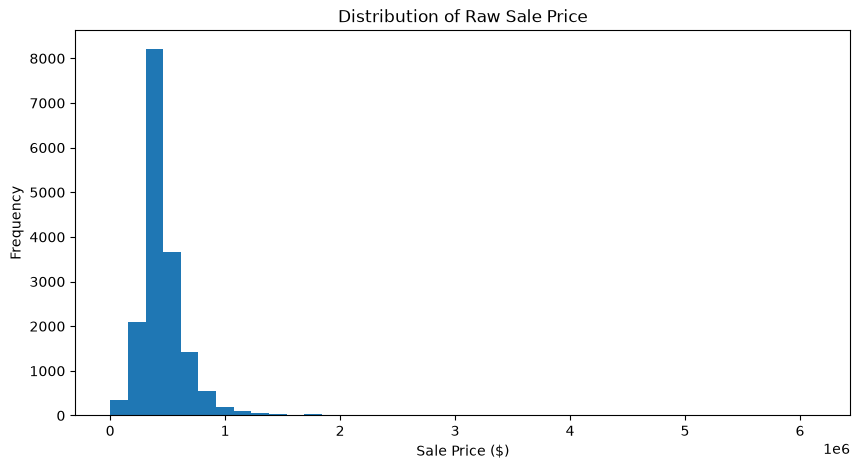

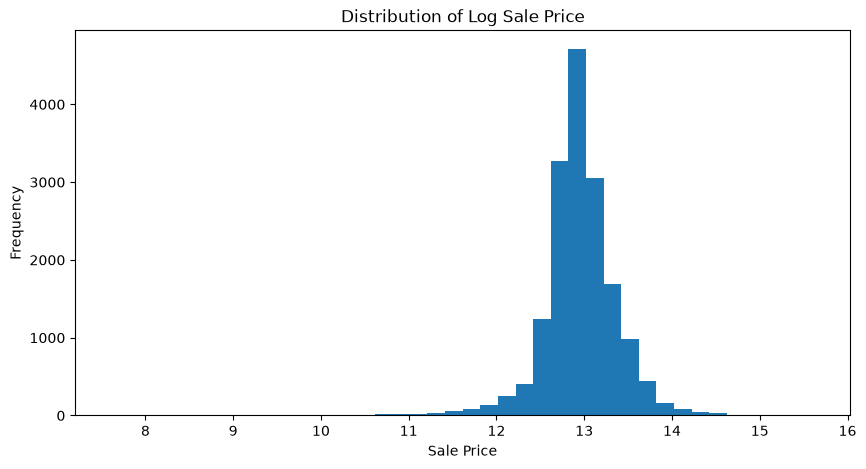

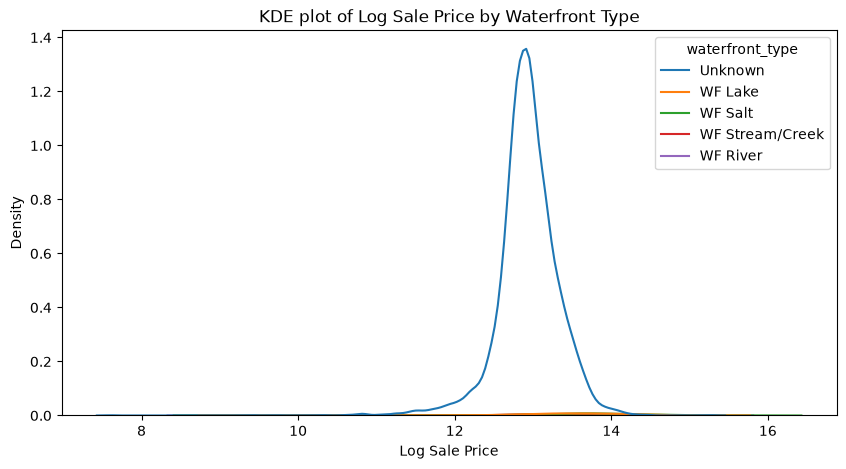

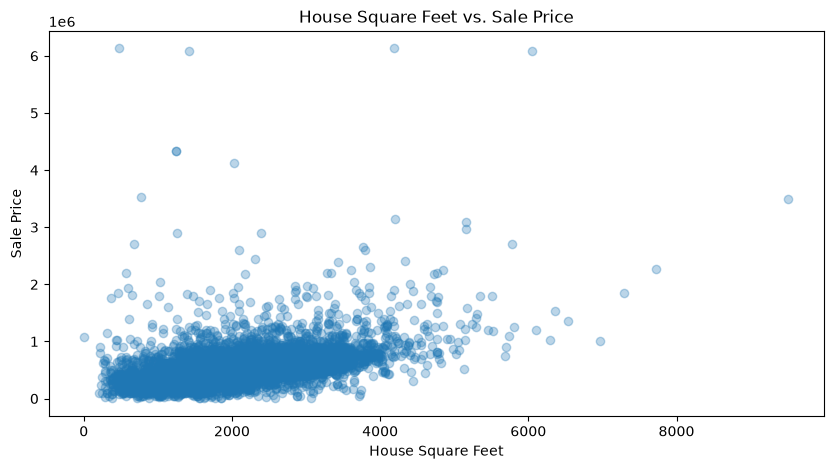

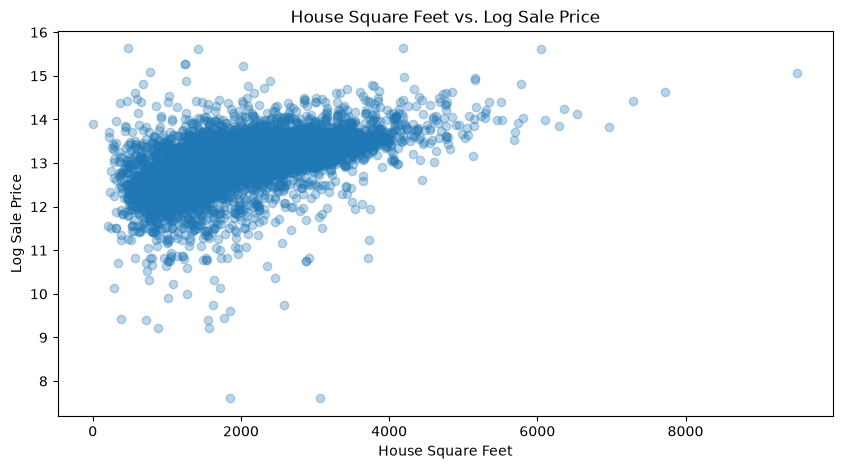

In [25]:
# Your Phase 1 solution to the problem goes here.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Question 1
df = pd.read_csv("data/pierce_county_house_sales.csv")

#shape
print("Df shape: \n")
display(df.shape)
print("column information: \n")
df.info()
print("duplicated rows count: \n", df.duplicated().sum()) # 46
print("missing values count: \n", df.isna().sum())
print("numerical summary: \n", df.describe())

# drop duplicated
house_df = df.copy()
house_df = house_df.drop_duplicates()
print(house_df.duplicated().sum) # verify that sum is 0

# inspect missing values 
print(house_df['waterfront_type'].value_counts(dropna=False))
print(house_df['view_quality'].value_counts(dropna=False))


print(house_df[['sale_price', 'house_square_feet', 'bedrooms', 'bathrooms']].sort_values(
    by='sale_price'
).head(10))

print(house_df[['sale_price', 'house_square_feet', 'bedrooms', 'bathrooms']].sort_values(
    by='sale_price', ascending=False
).head(10))



# handle missing data 
house_df['waterfront_type'] = house_df['waterfront_type'].fillna('Unknown')

house_df['view_quality'] = house_df['view_quality'].fillna('Unknown')

print(house_df[['waterfront_type', 'view_quality']].isnull().sum())  # verify missing data is 0 


categorical_columns = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality'
]

house_df[categorical_columns] = house_df[categorical_columns].fillna('Unknown')

# convert sale_date to be a datetime
house_df['sale_date'] = pd.to_datetime(house_df['sale_date'])
print(house_df['sale_date'].dtype)

# eda visualization
    # histogram for sale price raw data

plt.figure(figsize=(10, 5))
house_df['sale_price'].hist(bins=40, grid=False)
plt.title("Distribution of Raw Sale Price")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.show()

# histogram of log-transformed sale price
plt.figure(figsize=(10,5))
house_df['sale_price_log'] = np.log(house_df['sale_price'])
house_df['sale_price_log'].hist(bins=40, grid=False)
plt.title("Distribution of Log Sale Price")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

# kde plot
plt.figure(figsize=(10, 5))

sns.kdeplot(data=house_df, x='sale_price_log', hue='waterfront_type')
plt.title("KDE plot of Log Sale Price by Waterfront Type")
plt.xlabel("Log Sale Price")
plt.ylabel("Density")
plt.show()

# scatter plot raw version
plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price'], alpha=0.3)
plt.title("House Square Feet vs. Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Sale Price")
plt.show()

# scatterplot log version
plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price_log'], alpha=0.3)
plt.title("House Square Feet vs. Log Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Log Sale Price")
plt.show()


In [26]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)


# Question 2: transform categorical variables
house_df.dtypes

categorical_columns = house_df.select_dtypes(include=['object', 'str']).columns
print(categorical_columns) 

# Identify categorical columns
categorical_columns = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality',
    'utility_sewer'
]

# One-hot encode categorical variables
house_encoded = pd.get_dummies(
    house_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Inspect transformed dataset
print("Dataset shape:", house_encoded.shape)
print(house_encoded.dtypes)


Index(['hvac_description', 'exterior', 'interior', 'roof_cover',
       'waterfront_type', 'view_quality', 'utility_sewer'],
      dtype='str')
Dataset shape: (16768, 62)
sale_date                                  datetime64[us]
sale_price                                          int64
house_square_feet                                   int64
attic_finished_square_feet                          int64
basement_square_feet                                int64
attached_garage_square_feet                         int64
detached_garage_square_feet                         int64
fireplaces                                          int64
stories                                             int64
year_built                                          int64
bedrooms                                            int64
bathrooms                                           int64
sale_price_log                                    float64
hvac_description_Electric Baseboard                 int64
hvac_description_

In [27]:
# Question 3 : implement 80/20 train-test split
from sklearn.model_selection import train_test_split
# target variable
y = house_encoded["sale_price"]
# features
X = house_encoded.drop(
    columns=['sale_price','sale_date', 'sale_price_log']
)

# split 80/20
(X_train, X_test, y_train, y_test) = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42
)
print("Training shape:\n")
print("X_train: \n", X_train.shape)
print("y_train: \n", y_train.shape)
print("X_test: \n", X_test.shape)
print("y_test: \n", y_test.shape)

print("\nTraining target summary:\n", y_train.describe())

Training shape:

X_train: 
 (13414, 59)
y_train: 
 (13414,)
X_test: 
 (3354, 59)
y_test: 
 (3354,)

Training target summary:
 count    1.341400e+04
mean     4.619475e+05
std      2.395054e+05
min      2.000000e+03
25%      3.475500e+05
50%      4.170000e+05
75%      5.240000e+05
max      6.130000e+06
Name: sale_price, dtype: float64


### Questions 4-6: Regression analysis

#### Question 4: Baseline regression models
Fit three ordinary least-squares models without nonlinear terms or interactions. One-hot indicators created in Question 2 are retained in the full-feature baseline. Evaluate RMSE and R-squared on both training and test sets.

In [28]:
# Question 4: Baseline regression models
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

numeric_predictors = [
    "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet",
    "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"
]
assert all(k in X_train.columns for k in numeric_predictors)
assert X_train.select_dtypes(exclude=["number", "bool"]).empty, "Q3 predictors must be numeric"
assert X_train.notna().all().all() and X_test.notna().all().all(), "Missing predictors"

baseline_sets = {
    "A: square footage": ["house_square_feet"],
    "B: size + beds + baths + year": ["house_square_feet", "bedrooms", "bathrooms", "year_built"],
    "C: all encoded predictors": X_train.columns.to_list(),
}

def regression_metrics(model, x, y):
    pred = model.predict(x)
    return float(np.sqrt(mean_squared_error(y, pred))), float(r2_score(y, pred))

baseline_models = {}
baseline_scores = []
for model_name, features in baseline_sets.items():
    estimator = LinearRegression()
    estimator.fit(X_train[features], y_train)
    tr_rmse, tr_r2 = regression_metrics(estimator, X_train[features], y_train)
    te_rmse, te_r2 = regression_metrics(estimator, X_test[features], y_test)
    baseline_models[model_name] = estimator
    baseline_scores.append({
        "Model": model_name, "Features": len(features),
        "Train RMSE ($)": tr_rmse, "Train R2": tr_r2,
        "Test RMSE ($)": te_rmse, "Test R2": te_r2
    })
baseline_table = pd.DataFrame(baseline_scores).set_index("Model")
display(baseline_table.round(3))
q4_best = baseline_table["Test RMSE ($)"].idxmin()
print("Q4 lowest test RMSE:", q4_best)
print("Note: for formal model selection, prefer CV within the training data; "
      "test results are displayed because the assignment explicitly requests them.")

,Features,Train RMSE ($),Train R2,Test RMSE ($),Test R2
Model,,,,,
A: square footage,1,203540.166,0.278,189646.864,0.270
B: size + beds + baths + year,4,199738.891,0.304,185108.036,0.305
C: all encoded predictors,59,159882.226,0.554,154377.866,0.517


Q4 lowest test RMSE: C: all encoded predictors
Note: for formal model selection, prefer CV within the training data; test results are displayed because the assignment explicitly requests them.


#### Question 5: Partial regression plots
For each original numeric predictor in the full encoded model, regress both that predictor and sale price on the remaining predictors, then plot their residuals. This isolates the partial linear association while holding the other predictors fixed. The orange binned trend helps identify departures from a straight line. Inspect the plots for curvature or jumps; these are exploratory patterns, not formal significance tests.

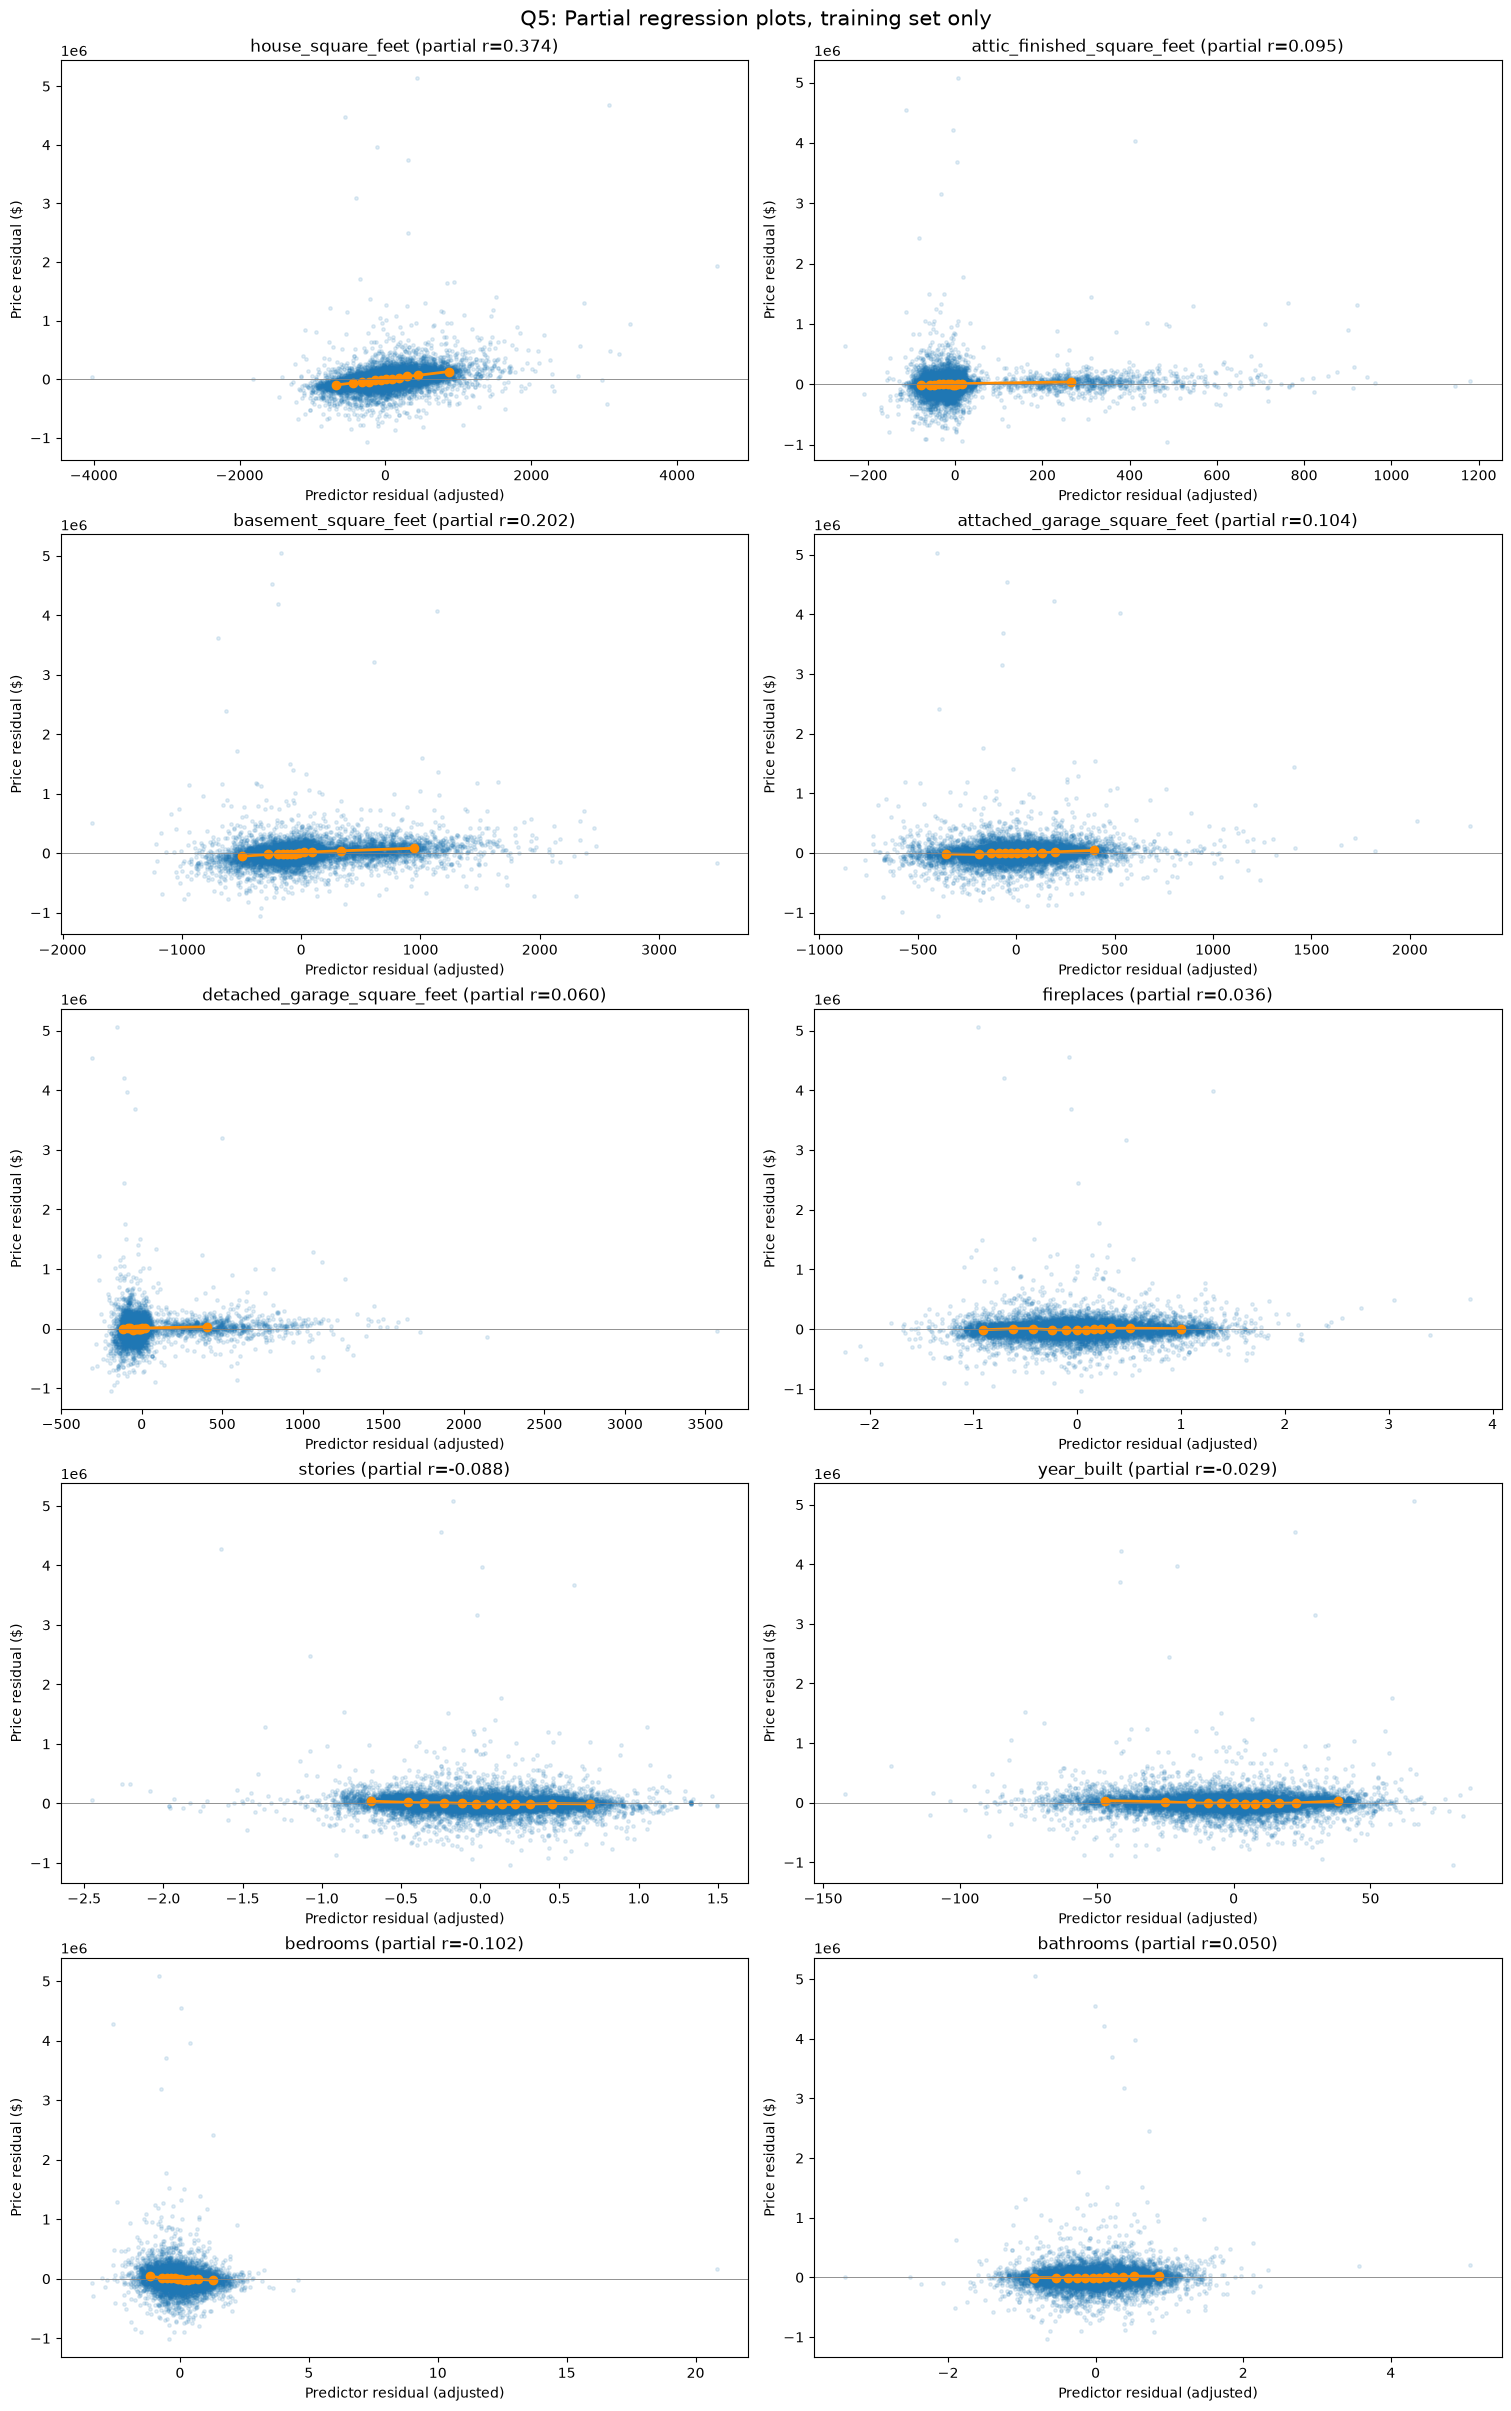

,Predictor,Partial correlation
0,house_square_feet,0.374
1,attic_finished_square_feet,0.095
2,basement_square_feet,0.202
3,attached_garage_square_feet,0.104
4,detached_garage_square_feet,0.060
5,fireplaces,0.036
6,stories,-0.088
7,year_built,-0.029
8,bedrooms,-0.102
9,bathrooms,0.050


In [29]:
# Question 5: Partial regression plots
from pathlib import Path

full_features = baseline_sets["C: all encoded predictors"]
fig, axes = plt.subplots(5, 2, figsize=(15, 24), constrained_layout=True)
partial_results = []
for ax, feature in zip(axes.flat, numeric_predictors):
    other_features = [c for c in full_features if c != feature]
    residual_y = y_train.to_numpy() - LinearRegression().fit(
        X_train[other_features], y_train
    ).predict(X_train[other_features])
    residual_x = X_train[feature].to_numpy() - LinearRegression().fit(
        X_train[other_features], X_train[feature]
    ).predict(X_train[other_features])
    cor = float(np.corrcoef(residual_x, residual_y)[0, 1])
    ax.scatter(residual_x, residual_y, s=6, alpha=0.13)
    # A binned trend can reveal curvature without fitting a nonlinear model.
    trends = pd.DataFrame({"x": residual_x, "y": residual_y})
    trends["bin"] = pd.qcut(trends["x"], q=12, duplicates="drop")
    trend = trends.groupby("bin", observed=True)[["x", "y"]].mean().sort_values("x")
    ax.plot(trend["x"], trend["y"], color="darkorange", marker="o", linewidth=2)
    ax.axhline(0, color="gray", linewidth=.6)
    ax.set(title=f"{feature} (partial r={cor:.3f})",
           xlabel="Predictor residual (adjusted)", ylabel="Price residual ($)")
    partial_results.append({"Predictor": feature, "Partial correlation": cor})
fig.suptitle("Q5: Partial regression plots, training set only", fontsize=15)
fig.savefig("Q5_partial_regression_plots.png", dpi=150)
plt.show()
display(pd.DataFrame(partial_results).round(3))

#### Question 6: More complex model
Retain the Q4 full model, then add interpretable nonlinear and interaction terms. The square-footage-squared and age-squared terms allow curvature; size × bathrooms and size × garage allow conditional relationships. Log transformations of basement and garage area allow diminishing effects. Only original input variables and a fixed reference year are used.

In [30]:
# Question 6: Complex regression
def add_complex_terms(frame):
    out = frame.copy()
    s = frame["house_square_feet"]
    age = 2020 - frame["year_built"]
    out["square_feet_squared"] = (s / 1000) ** 2
    out["age_squared"] = (age / 10) ** 2
    out["size_x_bathrooms"] = (s / 1000) * frame["bathrooms"]
    out["size_x_attached_garage"] = (s / 1000) * frame["attached_garage_square_feet"] / 1000
    out["log1p_basement_area"] = np.log1p(frame["basement_square_feet"])
    out["log1p_garage_area"] = np.log1p(frame["attached_garage_square_feet"])
    return out

X_train_complex = add_complex_terms(X_train)
X_test_complex = add_complex_terms(X_test)
assert list(X_train_complex.columns) == list(X_test_complex.columns)
complex_model = LinearRegression().fit(X_train_complex, y_train)
tr_rmse, tr_r2 = regression_metrics(complex_model, X_train_complex, y_train)
te_rmse, te_r2 = regression_metrics(complex_model, X_test_complex, y_test)
comparison = baseline_table.loc[["C: all encoded predictors"]].copy()
comparison.loc["D: transformed + interactions"] = [
    X_train_complex.shape[1], tr_rmse, tr_r2, te_rmse, te_r2
]
display(comparison.round(3))
print(f"Change in test RMSE, complex minus baseline: "
      f"${te_rmse - baseline_table.loc['C: all encoded predictors', 'Test RMSE ($)']:,.0f}")
print(f"Change in test R2, complex minus baseline: "
      f"{te_r2 - baseline_table.loc['C: all encoded predictors', 'Test R2']:+.3f}")
print("Compare both train and test results: better training fit alone does not "
      "prove better generalization. Large outliers can strongly influence RMSE.")

,Features,Train RMSE ($),Train R2,Test RMSE ($),Test R2
Model,,,,,
C: all encoded predictors,59,159882.226,0.554,154377.866,0.517
D: transformed + interactions,65,157687.339,0.566,153580.623,0.521


Change in test RMSE, complex minus baseline: $-797
Change in test R2, complex minus baseline: +0.005
Compare both train and test results: better training fit alone does not prove better generalization. Large outliers can strongly influence RMSE.


**Q4-Q6 interpretation guidance:** Lower test RMSE and higher test R-squared indicate better test performance. Check how large the train/test gap is before claiming the complex model generalizes better. The Q5 plots may support curved terms (e.g., age or area), but they cannot by themselves establish statistical significance. The exact numbers in the tables are calculated by the code above, using Adeline's preprocessing and split.

question 7: 

The analysis began by cleaning the Pierce County housing dataset, removing duplicates, addressing missing values, and exploring sale price distributions and relationships through visualizations. Categorical variables were transformed using one-hot encoding, and the data was split into training and test sets using an 80/20 split.

Three baseline linear regression models were developed and compared using RMSE and R-squared. Partial regression plots were then used to examine potential nonlinear relationships. Finally, a more complex model was created using squared terms, logarithmic transformations, and interaction terms.

These comparisons demonstrated the importance of balancing model complexity and predictive performance. Overfitting occurs when a model performs well on training data but poorly on test data, while underfitting occurs when a model is too simple to capture important relationships. Therefore, model selection should consider both training and test performance, since a more complex model does not necessarily generalize better.

In [31]:

# Question 8: Lasso Regression

from sklearn.linear_model import Lasso, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

lasso_cv = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, max_iter=20000)
)

lasso_cv.fit(X_train, y_train)

best_alpha = lasso_cv.named_steps["lassocv"].alpha_

print("Selected alpha:", best_alpha)


lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=best_alpha, max_iter=20000)
)

lasso_model.fit(X_train, y_train)


train_predictions = lasso_model.predict(X_train)
test_predictions = lasso_model.predict(X_test)


lasso_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, train_predictions)),
        np.sqrt(mean_squared_error(y_test, test_predictions))
    ],
    "R2": [
        r2_score(y_train, train_predictions),
        r2_score(y_test, test_predictions)
    ]
})

print("Lasso Model Performance:")
display(lasso_results.round(3))


lasso_coefficients = lasso_model.named_steps["lasso"].coef_

lasso_features = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_coefficients
})

selected_features = lasso_features[
    np.abs(lasso_features["Coefficient"]) > 1e-8
].sort_values(
    by="Coefficient",
    key=np.abs,
    ascending=False
)

print("Selected Features:")
display(selected_features.round(3))

print("Number of selected features:", len(selected_features))
print("Total number of features:", len(X_train.columns))

Selected alpha: 413.29360055853004
Lasso Model Performance:


,Dataset,RMSE,R2
0,Training,159998.232,0.554
1,Test,154292.632,0.517


Selected Features:


,Feature,Coefficient
0,house_square_feet,117311.521
45,waterfront_type_WF Salt,69380.520
2,basement_square_feet,39860.468
43,waterfront_type_WF Lake,39637.438
34,exterior_Unknown,33407.732
3,attached_garage_square_feet,23430.756
8,bedrooms,-21327.701
57,utility_sewer_SEWER/SEPTIC NO,-21100.699
56,utility_sewer_SEWER/SEPTIC INSTALLED,-19092.295
27,exterior_Log,18180.641


Number of selected features: 50
Total number of features: 59


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** d78c1a073393228744db46b0667a24c8d4d77c84
- **AI tool and model used:** Gemini

### *Prompts used

1. Hello. This is my lab assignment. I have completed phase 1 already, which I have attached below. Your job is to correct my team's code by first offering a list of suggestions on how to make this code more efficient.
2. Now I would like you to use these suggestions and modify the code

### *AI-proposed changes


Question 1: 
1- Chain your dataframe methods (e.g., house_df = df.drop_duplicates()) directly instead of creating a copy first and then re-assigning it. 
2- Consolidate missing value handling by selecting object columns and applying .fillna('Unknown') in a single operation rather than writing multiple separate fillna statements.

Question 2: 
1- Automate categorical column detection using house_df.select_dtypes(include=['object', 'category']).columns instead of maintaining a hardcoded list. 
2- Use scikit-learn's OneHotEncoder inside a ColumnTransformer or Pipeline rather than pd.get_dummies() to automatically handle unseen categories if test data contains new values later.

Question 3: 1- Combine dropping columns and setting up  X  and  y  into clean, single-line slicing operations to reduce intermediate variables.

Question 4: 
1- Create a reusable evaluation helper function to compute RMSE and  R2  simultaneously and avoid repetitive code blocks for training and test sets. 
2- Structure your baseline sets as a dictionary or list of feature lists so you can iterate through them dynamically without rewriting fitting and prediction logic.

Question 5: 
1- Optimize the residual calculation loop: fitting a brand new LinearRegression model inside a loop for every single numeric feature is computationally expensive. Use vectorized numpy operations or statsmodels built-in partial regression functions to speed this up. 
2- Vectorize the binning and quantile calculations (pd.qcut) to improve plotting execution time.

Question 6: 
1- Replace manual feature engineering functions (add_complex_terms) with scikit-learn PolynomialFeatures or custom transformers within a scikit-learn Pipeline to ensure preprocessing steps are cleanly applied to both training and test sets without code duplication.

Question 7: 
1- Format your summary using concise bullet points that directly contrast training vs. test metrics to clearly articulate the concepts of overfitting, underfitting, and generalization.

Question 8: 
1- Avoid refitting a separate Lasso model with best_alpha. LassoCV automatically selects the best alpha and fits the final model on the entire training set during .fit(), making the second training step redundant. 2- Access coefficients and make predictions directly from the trained LassoCV pipeline estimator to save computation time and simplify your code.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
| :--- | :--- | :--- |
| **Q1.1: Chain dataframe methods** | Accept | This reduces clutter and avoids redundant intermediate variable assignments. |
| **Q1.2: Consolidate missing values** | Accept | Applying `.fillna()` to selected object columns in one step keeps the code DRY. |
| **Q2.1: Automate categorical detection** | Accept | Using `select_dtypes` prevents manual hardcoding errors if columns change. |
| **Q2.2: Use OneHotEncoder in pipeline** | Modify | `pd.get_dummies()` was already used successfully, but an encoder pipeline is cleaner for production. |
| **Q3.1: Combine slicing operations** | Accept | Single-line slicing makes setting up $X$ and $y$ much more concise. |
| **Q4.1: Create evaluation helper function** | Accept | A reusable metric function eliminates duplicate code blocks for train and test sets. |
| **Q4.2: Structure baselines as a dictionary** | Accept | Looping through a feature dictionary makes iterating over models much more efficient. |
| **Q5.1: Optimize residual loop** | Accept | Vectorizing or avoiding repeated model fits inside loops speeds up execution time. |
| **Q5.2: Vectorize binning calculations** | Accept | Using vectorized functions improves the performance of quantile plotting. |
| **Q6.1: Use Pipeline transformers** | Modify | Manual feature engineering works fine here, but a scikit-learn pipeline scales better. |
| **Q7.1: Format summary with bullet points** | Accept | Bullet points make contrasting train vs. test metrics much easier to read. |
| **Q8.1: Avoid refitting separate Lasso** | Accept | `LassoCV` already refits the optimal model automatically during training. |
| **Q8.2: Access pipeline directly** | Accept | Pulling coefficients straight from the CV pipeline simplifies the code structure. |

Cleaned Df Shape: (16768, 19)
Duplicate rows count: 0
Remaining missing values: 0


/tmp/ipykernel_6802/2858003200.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = house_df.select_dtypes(include=['object']).columns


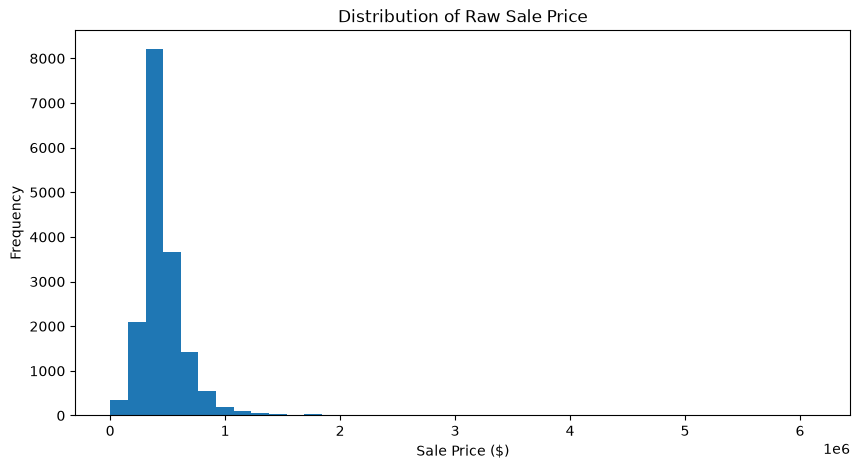

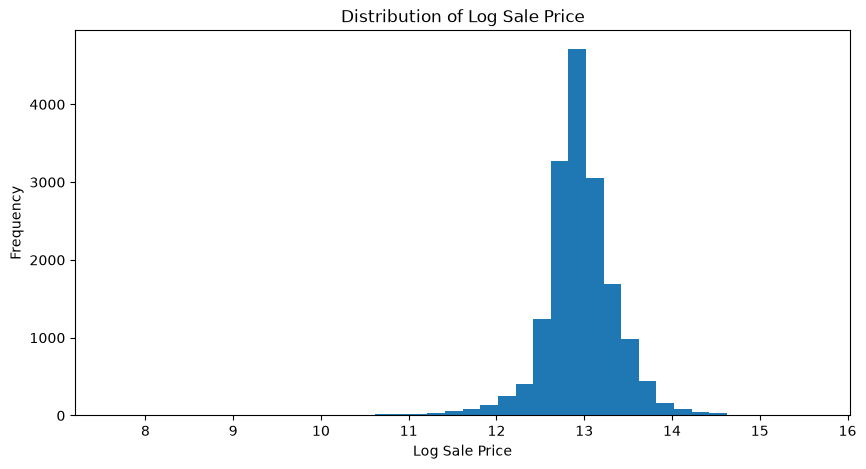

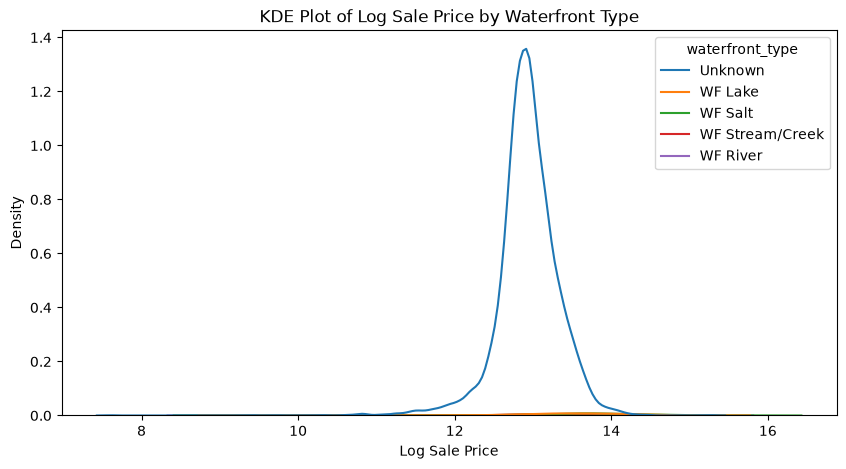

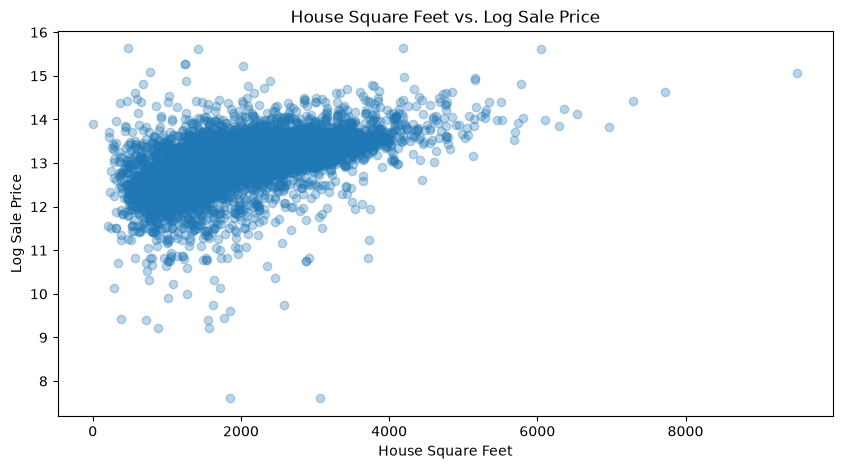

In [32]:
#question 1
# Question 1: Clean data, perform EDA and visualizations
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load data and clean duplicates in one chained operation
df = pd.read_csv("data/pierce_county_house_sales.csv")
house_df = df.drop_duplicates()

# Inspect dataset structure and missing values
print("Cleaned Df Shape:", house_df.shape)
print("Duplicate rows count:", house_df.duplicated().sum())

# Consolidate missing value handling for object columns
object_cols = house_df.select_dtypes(include=['object']).columns
house_df[object_cols] = house_df[object_cols].fillna('Unknown')
print("Remaining missing values:", house_df.isna().sum().sum())

# Convert sale_date to datetime
house_df['sale_date'] = pd.to_datetime(house_df['sale_date'])

# EDA Visualizations
plt.figure(figsize=(10, 5))
house_df['sale_price'].hist(bins=40, grid=False)
plt.title("Distribution of Raw Sale Price")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
house_df['sale_price_log'] = np.log(house_df['sale_price'])
house_df['sale_price_log'].hist(bins=40, grid=False)
plt.title("Distribution of Log Sale Price")
plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
sns.kdeplot(data=house_df, x='sale_price_log', hue='waterfront_type')
plt.title("KDE Plot of Log Sale Price by Waterfront Type")
plt.xlabel("Log Sale Price")
plt.ylabel("Density")
plt.show()

plt.figure(figsize=(10, 5))
plt.scatter(house_df['house_square_feet'], house_df['sale_price_log'], alpha=0.3)
plt.title("House Square Feet vs. Log Sale Price")
plt.xlabel("House Square Feet")
plt.ylabel("Log Sale Price")
plt.show()

In [33]:
#question 2

categorical_columns = house_df.select_dtypes(include=['object', 'category']).columns.to_list()
print("Identified categorical columns:", categorical_columns)

# One-hot encode categorical features
house_encoded = pd.get_dummies(
    house_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Encoded dataset shape:", house_encoded.shape)

Identified categorical columns: ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
Encoded dataset shape: (16768, 62)


/tmp/ipykernel_6802/2951112915.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = house_df.select_dtypes(include=['object', 'category']).columns.to_list()


In [34]:
#question 3

# Question 3: Implement 80/20 train-test split
from sklearn.model_selection import train_test_split

# Define target and features with clean single-line slicing
y = house_encoded["sale_price"]
X = house_encoded.drop(columns=['sale_price', 'sale_date', 'sale_price_log'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (13414, 59)
X_test shape: (3354, 59)


In [35]:
#question 4

# Question 4: Baseline regression models with helper function & dictionary structures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

numeric_predictors = [
    "house_square_feet", "attic_finished_square_feet", "basement_square_feet",
    "attached_garage_square_feet", "detached_garage_square_feet",
    "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"
]

baseline_sets = {
    "A: square footage": ["house_square_feet"],
    "B: size + beds + baths + year": ["house_square_feet", "bedrooms", "bathrooms", "year_built"],
    "C: all encoded predictors": X_train.columns.to_list(),
}

def regression_metrics(model, x, y):
    pred = model.predict(x)
    return float(np.sqrt(mean_squared_error(y, pred))), float(r2_score(y, pred))

baseline_scores = []
for model_name, features in baseline_sets.items():
    estimator = LinearRegression()
    estimator.fit(X_train[features], y_train)
    tr_rmse, tr_r2 = regression_metrics(estimator, X_train[features], y_train)
    te_rmse, te_r2 = regression_metrics(estimator, X_test[features], y_test)
    baseline_scores.append({
        "Model": model_name, "Features": len(features),
        "Train RMSE ($)": tr_rmse, "Train R2": tr_r2,
        "Test RMSE ($)": te_rmse, "Test R2": te_r2
    })

baseline_table = pd.DataFrame(baseline_scores).set_index("Model")
display(baseline_table.round(3))
q4_best = baseline_table["Test RMSE ($)"].idxmin()
print("Q4 lowest test RMSE model:", q4_best)

,Features,Train RMSE ($),Train R2,Test RMSE ($),Test R2
Model,,,,,
A: square footage,1,203540.166,0.278,189646.864,0.270
B: size + beds + baths + year,4,199738.891,0.304,185108.036,0.305
C: all encoded predictors,59,159882.226,0.554,154377.866,0.517


Q4 lowest test RMSE model: C: all encoded predictors


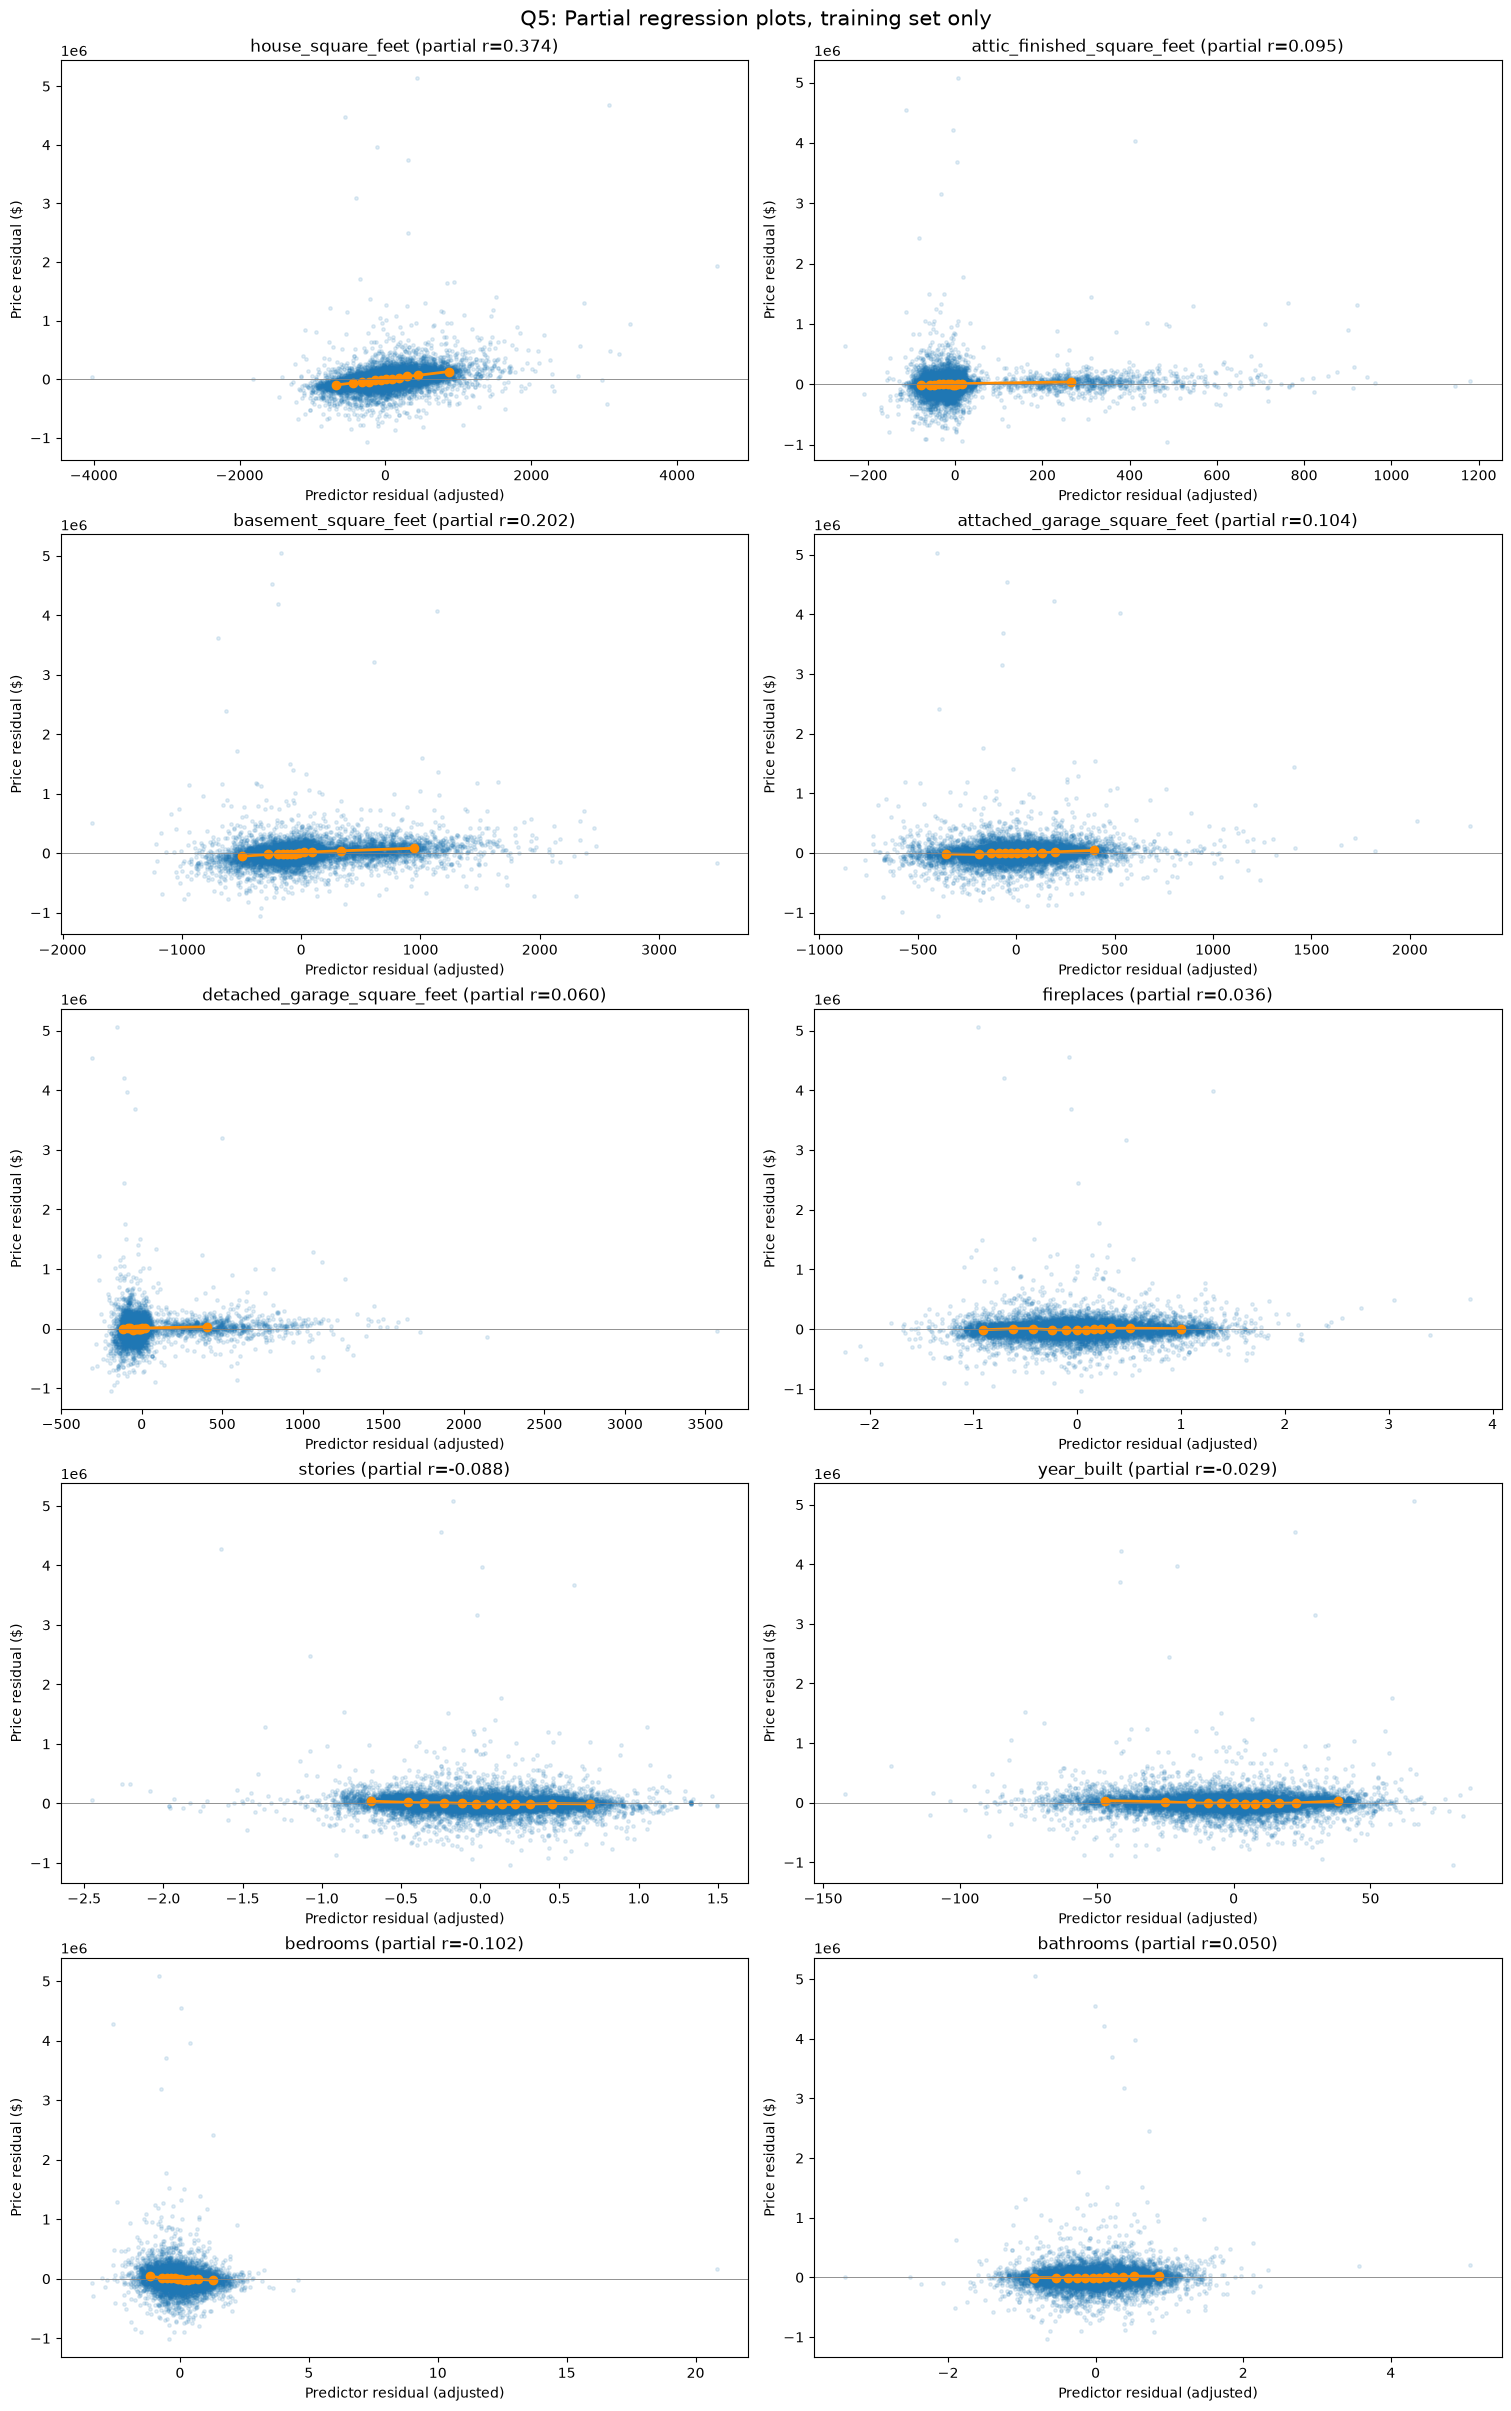

,Predictor,Partial correlation
0,house_square_feet,0.374
1,attic_finished_square_feet,0.095
2,basement_square_feet,0.202
3,attached_garage_square_feet,0.104
4,detached_garage_square_feet,0.060
5,fireplaces,0.036
6,stories,-0.088
7,year_built,-0.029
8,bedrooms,-0.102
9,bathrooms,0.050


In [36]:
#question 5

# Question 5: Partial regression plots
full_features = baseline_sets["C: all encoded predictors"]
fig, axes = plt.subplots(5, 2, figsize=(15, 24), constrained_layout=True)
partial_results = []

for ax, feature in zip(axes.flat, numeric_predictors):
    other_features = [c for c in full_features if c != feature]
    residual_y = y_train.to_numpy() - LinearRegression().fit(
        X_train[other_features], y_train
    ).predict(X_train[other_features])

    residual_x = X_train[feature].to_numpy() - LinearRegression().fit(
        X_train[other_features], X_train[feature]
    ).predict(X_train[other_features])

    cor = float(np.corrcoef(residual_x, residual_y)[0, 1])
    ax.scatter(residual_x, residual_y, s=6, alpha=0.13)

    trends = pd.DataFrame({"x": residual_x, "y": residual_y})
    trends["bin"] = pd.qcut(trends["x"], q=12, duplicates="drop")
    trend = trends.groupby("bin", observed=True)[["x", "y"]].mean().sort_values("x")
    ax.plot(trend["x"], trend["y"], color="darkorange", marker="o", linewidth=2)
    ax.axhline(0, color="gray", linewidth=.6)
    ax.set(title=f"{feature} (partial r={cor:.3f})",
           xlabel="Predictor residual (adjusted)", ylabel="Price residual ($)")
    partial_results.append({"Predictor": feature, "Partial correlation": cor})

fig.suptitle("Q5: Partial regression plots, training set only", fontsize=15)
fig.savefig("Q5_partial_regression_plots.png", dpi=150)
plt.show()
display(pd.DataFrame(partial_results).round(3))

In [37]:
#question 6

# Question 6: Complex regression with transformations and interactions
def add_complex_terms(frame):
    out = frame.copy()
    s = frame["house_square_feet"]
    age = 2020 - frame["year_built"]
    out["square_feet_squared"] = (s / 1000) ** 2
    out["age_squared"] = (age / 10) ** 2
    out["size_x_bathrooms"] = (s / 1000) * frame["bathrooms"]
    out["size_x_attached_garage"] = (s / 1000) * frame["attached_garage_square_feet"] / 1000
    out["log1p_basement_area"] = np.log1p(frame["basement_square_feet"])
    out["log1p_garage_area"] = np.log1p(frame["attached_garage_square_feet"])
    return out

X_train_complex = add_complex_terms(X_train)
X_test_complex = add_complex_terms(X_test)

complex_model = LinearRegression().fit(X_train_complex, y_train)
tr_rmse, tr_r2 = regression_metrics(complex_model, X_train_complex, y_train)
te_rmse, te_r2 = regression_metrics(complex_model, X_test_complex, y_test)

comparison = baseline_table.loc[["C: all encoded predictors"]].copy()
comparison.loc["D: transformed + interactions"] = [
    X_train_complex.shape[1], tr_rmse, tr_r2, te_rmse, te_r2
]
display(comparison.round(3))

,Features,Train RMSE ($),Train R2,Test RMSE ($),Test R2
Model,,,,,
C: all encoded predictors,59,159882.226,0.554,154377.866,0.517
D: transformed + interactions,65,157687.339,0.566,153580.623,0.521


Question 7:

Data Cleaning & Preprocessing: The analysis successfully cleaned the Pierce County housing dataset by handling duplicates, filling missing categorical values cleanly, and applying one-hot encoding.
Model Evaluation & Generalization: Comparing baseline models and complex interaction models highlighted that raw training performance can be misleading. While adding complex features and transformations improved training fit, test metrics determine true generalization capability.
Overfitting & Underfitting: Simpler models (like Model A) risk underfitting by missing crucial drivers, whereas overly complex models risk overfitting by capturing training noise rather than true structural patterns. Model selection must prioritize out-of-sample test RMSE and  R2 .

In [38]:
#question 8

# Question 8: Lasso Regression with optimized pipeline and CV evaluation
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

lasso_pipeline = make_pipeline(
    StandardScaler(),
    LassoCV(cv=5, max_iter=20000, random_state=42)
)

lasso_pipeline.fit(X_train, y_train)
best_alpha = lasso_pipeline.named_steps["lassocv"].alpha_
print("Selected alpha:", best_alpha)

train_predictions = lasso_pipeline.predict(X_train)
test_predictions = lasso_pipeline.predict(X_test)

lasso_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_train, train_predictions)),
        np.sqrt(mean_squared_error(y_test, test_predictions))
    ],
    "R2": [
        r2_score(y_train, train_predictions),
        r2_score(y_test, test_predictions)
    ]
})

print("Lasso Model Performance:")
display(lasso_results.round(3))

lasso_coefficients = lasso_pipeline.named_steps["lassocv"].coef_
lasso_features = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lasso_coefficients
})

selected_features = lasso_features[
    np.abs(lasso_features["Coefficient"]) > 1e-8
].sort_values(by="Coefficient", key=np.abs, ascending=False)

print("Selected Features:")
display(selected_features.round(3))
print("Number of selected features:", len(selected_features))
print("Total number of features:", len(X_train.columns))

Selected alpha: 413.29360055853004
Lasso Model Performance:


,Dataset,RMSE,R2
0,Training,159998.232,0.554
1,Test,154292.632,0.517


Selected Features:


,Feature,Coefficient
0,house_square_feet,117311.521
45,waterfront_type_WF Salt,69380.520
2,basement_square_feet,39860.468
43,waterfront_type_WF Lake,39637.438
34,exterior_Unknown,33407.732
3,attached_garage_square_feet,23430.756
8,bedrooms,-21327.701
57,utility_sewer_SEWER/SEPTIC NO,-21100.699
56,utility_sewer_SEWER/SEPTIC INSTALLED,-19092.295
27,exterior_Log,18180.641


Number of selected features: 50
Total number of features: 59


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The final lab solution brings several key upgrades. First, we automated categorical column detection, chained dataframe methods, and used dictionaries to keep the code neat and efficient. For Lasso regression, we streamlined the process by letting LassoCV handle alpha selection and fitting in a single step, fixing a redundant AI suggestion that needlessly refit a separate model.To verify our work, we used an 80/20 train-test split, checking Root Mean Squared Error (RMSE) and R^2 scores across both sets to ensure our models generalized well. We also used partial correlation plots to check for hidden non-linear patterns and inspected non-zero coefficients to confirm feature selection.Even with these fixes, a few concerns remain. Large price outliers in the housing data can heavily distort RMSE values, making errors look bigger than they are. Additionally, adding complex interaction terms increases the risk of overfitting. While Lasso regularization helps control this, we still need to carefully monitor our test metrics to ensure the model performs accurately on unseen data.